# 컨베이어 카운터 오작동 리셋 — 기간 추이 (2026-09-10 ~ 10-14, 평일, 추석 9/24·25 제외)

규칙은 [Conv_Wagon_Reset_대차별_오작동리셋.ipynb](Conv_Wagon_Reset_대차별_오작동리셋.ipynb) 와 같다(Pour 리셋 = 대차 경계, 30초 무변화 사이클 통째로 제외, 직전 값 ≤100 인 감소 = 오작동 리셋, MD_CY_FWD 만 가장 가까운 Pour 리셋 번호).
추가: 날짜를 건너뛰어 이어 붙였기 때문에 **샘플이 30초 이상 빈 구간**(금요일 밤 → 월요일 아침 등)이 걸친 사이클도 뺀다.

데이터 받기: `PYTHONIOENCODING=utf-8 python parkkt/conv/conv_wagon_reset_pull.py` (하루씩 `parkkt/cache/conv_wagon_reset/daily/` 에 캐시, 오늘은 매번 새로 받음)

**대차 번호 = 실제 대차 번호.** 카운터마다 센서 앞에 있는 실제 대차로 바꿔 붙였다(`conv_wagon_reset.LABEL_OFFSET`, 근거는 기간추이 노트북 9절).
MD_CY_FWD·MD_CY_REV 는 '1번감지' 센서로, Opening 은 'Opening 다음 바로 전진Unit 에 같은 대차' 로 확인했고, Conv_Stop·Closing 은 대차 간격 무늬로 맞춘 값이다. `pour_wagon` 열은 Pour 기준 번호다.

In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath("../.."))
import importlib, conv_wagon_reset as cw, conv_wagon_reset_pull as cp
importlib.reload(cw); importlib.reload(cp)
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 260); pd.set_option("display.max_rows", 80)
plt.rc("font", family="Malgun Gothic" if os.name == "nt" else "AppleGothic"); plt.rc("axes", unicode_minus=False)
OUT = "../analysis_out/conv_wagon_reset/period"; os.makedirs(OUT, exist_ok=True)

df = cp.load_days()
print(df.shape, df.index.min(), "~", df.index.max())
print("날짜:", sorted({d.strftime('%m-%d') for d in df.index.normalize().unique()}))

(2500759, 15) 2026-09-10 00:00:00.330418 ~ 2026-10-14 16:02:05.854186
날짜: ['09-10', '09-11', '09-14', '09-15', '09-16', '09-17', '09-18', '09-21', '09-22', '09-23', '09-28', '09-29', '09-30', '10-01', '10-02', '10-05', '10-06', '10-07', '10-08', '10-09', '10-12', '10-13', '10-14']


## 1. 제외와 전제 확인

In [2]:
flats = cw.find_flats(df)
cyc = cw.pour_cycles(df, flats)
R = {n: cw.counter_resets(df, n, cyc) for n in cw.COUNTERS}
B = {n: cw.bursts(R[n]) for n in cw.COUNTERS}
print(f"Pour 사이클 {len(cyc)}개 중 제외 {int(cyc['flat'].sum())}개 → 남김 {int((~cyc['flat']).sum())}개")
print("남긴 Pour 사이클마다 카운터별 통과 횟수 (키: 통과 횟수, 값: 사이클 수)")
display(pd.DataFrame({n: cw.per_cycle_check(cyc, B[n]) for n in cw.COUNTERS}).fillna(0).astype(int))

Pour 사이클 100549개 중 제외 420개 → 남김 100129개
남긴 Pour 사이클마다 카운터별 통과 횟수 (키: 통과 횟수, 값: 사이클 수)


,Pour_Zone,Conv_Stop,MD_CY_FWD,Opening,Closing,MD_CY_REV
0,3,7,12,5,7,7
1,100126,100122,100113,100122,100122,100122
2,0,0,4,2,0,0


### 대차 번호가 +1 이 아닌 곳
주말·정지(제외 구간) 뒤에 번호가 몇 칸 건너뛴다 — 기록이 없는 동안 대차가 움직인 것. 그 밖에는 30초 미만 짧은 끊김에서 2칸 뛴 게 몇 번 있다.
MD_CY_FWD 의 실제 10·13·19·23·35 번은 이런 건너뜀을 지나서도 23일 내내 같은 번호로 걸린다(3번 셀) → **대차 번호가 실물 대차를 따라간다**고 본다.

In [3]:
st = cyc["wagon"].diff() % 42
j = np.flatnonzero((st != 1) & st.notna())
display(pd.DataFrame({"시각": cyc["start"].values[j], "이전 번호": cyc["wagon"].values[j - 1], "번호": cyc["wagon"].values[j],
                      "건너뜀": st.values[j].astype(int), "직전 사이클 초": cyc["dur_s"].values[j - 1].round(0),
                      "직전 사이클 제외됨": cyc["flat"].values[j - 1]}))

,시각,이전 번호,번호,건너뜀,직전 사이클 초,직전 사이클 제외됨
0,2026-09-11 15:10:05.690007,30,33,3,588.0,True
1,2026-09-14 05:06:30.358163,41,29,30,191192.0,True
2,2026-09-21 00:00:07.007406,16,28,12,172814.0,True
3,2026-09-28 00:03:15.661389,42,5,5,345808.0,True
4,2026-09-28 17:44:06.452303,13,15,2,28.0,False
5,2026-10-02 11:33:35.869738,32,34,2,33.0,False
6,2026-10-05 05:12:13.958324,23,21,40,191537.0,True
7,2026-10-06 08:02:01.806454,7,9,2,26.0,False
8,2026-10-08 16:04:10.873563,22,33,11,139.0,True
9,2026-10-12 04:59:06.327614,40,25,27,190754.0,True


## 2. 기간 전체 요약

In [4]:
S = cw.summary(cyc, B); display(S); S.to_csv(f"{OUT}/summary.csv", encoding="utf-8-sig")

,pour_cycles,passes,abn_passes,abn_pct,abn_resets,wagons_hit
counter,,,,,,
Pour_Zone,100129,100126,3,0.00,3,3
Conv_Stop,100129,100122,20,0.02,20,8
MD_CY_FWD,100129,100121,23683,23.65,34419,29
Opening,100129,100126,1639,1.64,1640,6
Closing,100129,100122,74,0.07,93,11
MD_CY_REV,100129,100122,1806,1.80,2511,16


## 3. 날짜별 오작동 통과 % (카운터별)

,pour_cycles,Pour_Zone,Conv_Stop,MD_CY_FWD,Opening,Closing,MD_CY_REV
time,,,,,,,
2026-09-10,4478,0.00,0.00,27.15,2.37,0.00,4.78
2026-09-11,4469,0.00,0.00,27.03,2.42,0.00,3.67
2026-09-14,4328,0.00,0.02,22.56,2.06,0.00,2.75
2026-09-15,4406,0.00,0.18,23.88,2.56,0.00,3.00
2026-09-16,4331,0.00,0.00,23.67,2.36,0.67,2.77
2026-09-17,4324,0.00,0.00,23.45,2.75,0.00,2.78
2026-09-18,4419,0.00,0.02,22.88,2.58,0.00,3.21
2026-09-21,4495,0.00,0.09,26.34,2.14,0.02,1.80
2026-09-22,4396,0.00,0.00,22.18,0.96,0.00,0.25


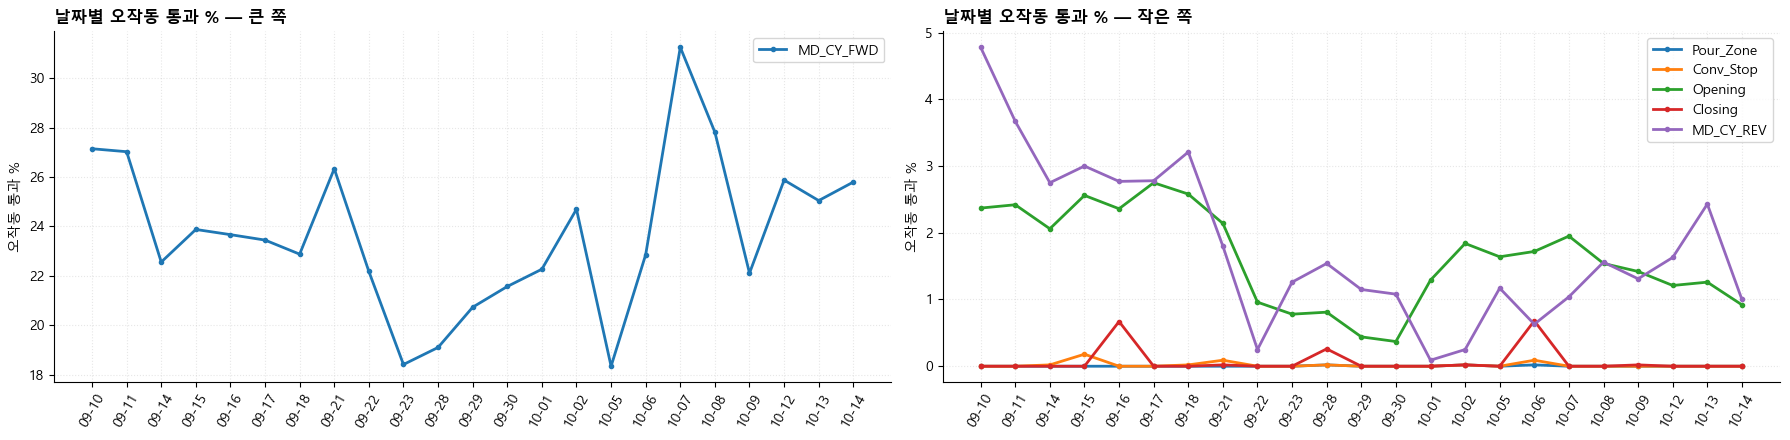

In [5]:
k = cyc[~cyc["flat"]]
D = pd.DataFrame({n: B[n][~B[n]["flat"]].groupby(B[n]["time"].dt.date)["abnormal"].mean().mul(100).round(2) for n in cw.COUNTERS})
D.insert(0, "pour_cycles", k.groupby("date").size())
display(D); D.to_csv(f"{OUT}/daily_pct.csv", encoding="utf-8-sig")

HIT = [n for n in cw.COUNTERS if S.loc[n, "abn_passes"] > 0]
x = [d.strftime("%m-%d") for d in D.index]
big = [n for n in HIT if D[n].max() >= 5]; small = [n for n in HIT if n not in big]
fig, ax = plt.subplots(1, 2, figsize=(18, 4.5))
for a, names in zip(ax, [big, small]):
    for n in names:
        a.plot(x, D[n], ".-", lw=2, label=n)
    a.legend(); a.grid(alpha=0.3, ls=":"); a.set_ylabel("오작동 통과 %"); a.tick_params(axis="x", rotation=60)
    a.spines[["top", "right"]].set_visible(False)
ax[0].set_title("날짜별 오작동 통과 % — 큰 쪽", fontweight="bold", loc="left")
ax[1].set_title("날짜별 오작동 통과 % — 작은 쪽", fontweight="bold", loc="left")
fig.tight_layout(); fig.savefig(f"{OUT}/daily_pct.png", dpi=100)

## 4. 대차 × 날짜 — 어느 대차가 언제 걸렸나
값 = 그 날 그 대차 통과 중 오작동 %. 하루라도 10% 이상인 대차만 그린다.

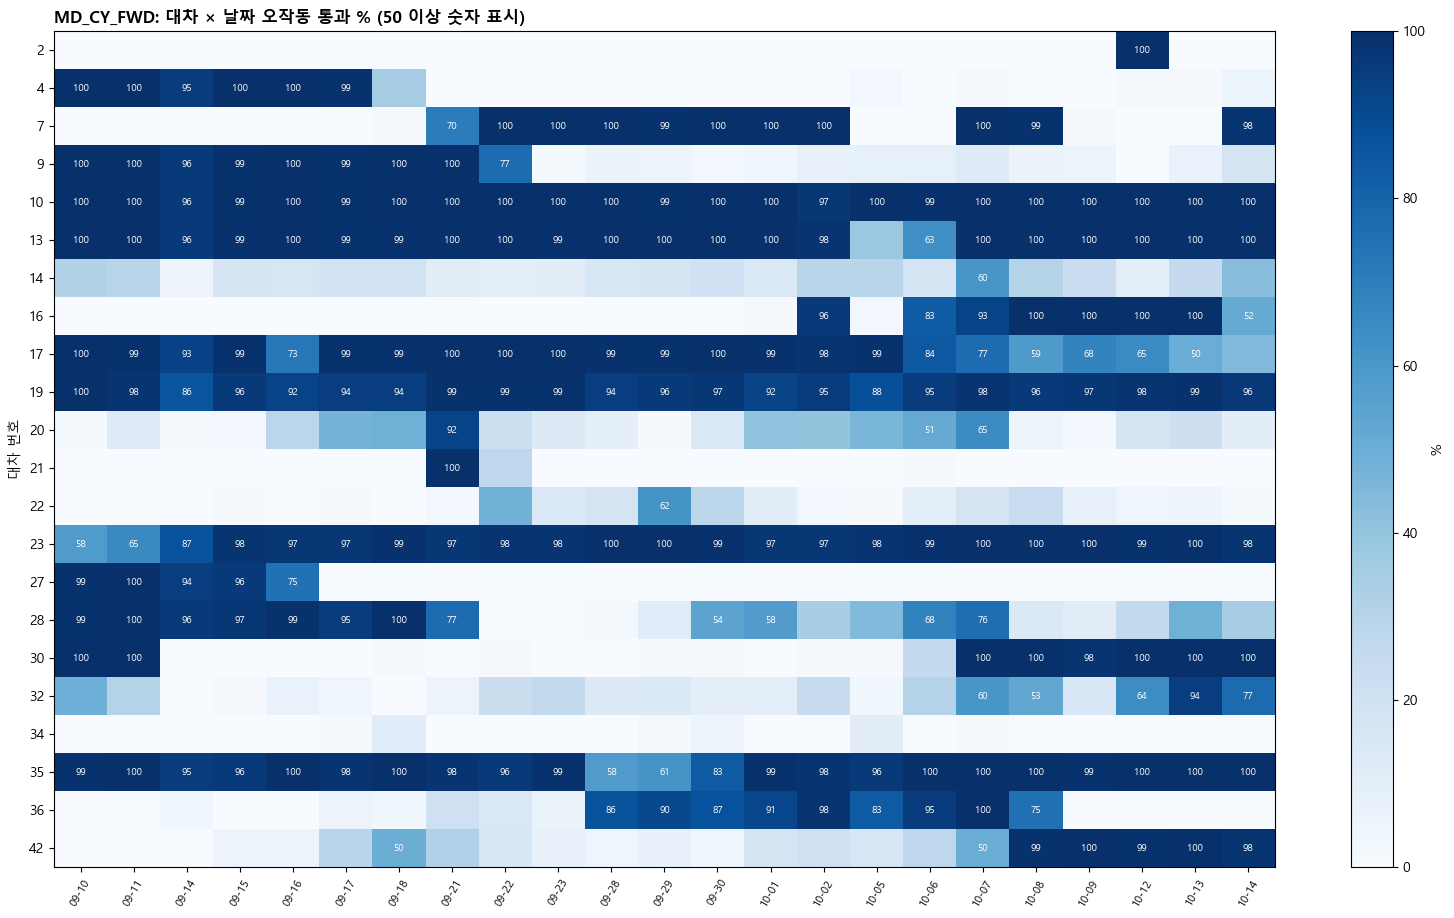

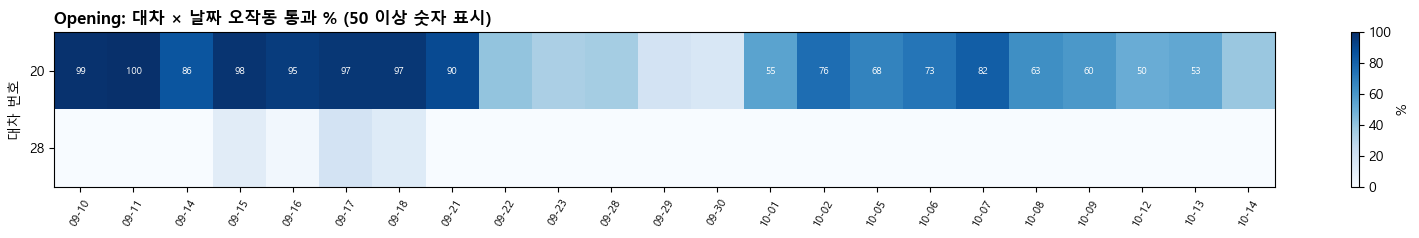

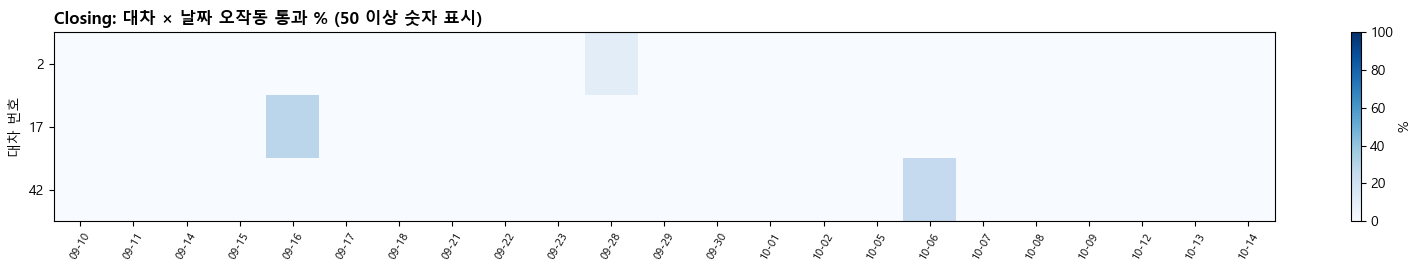

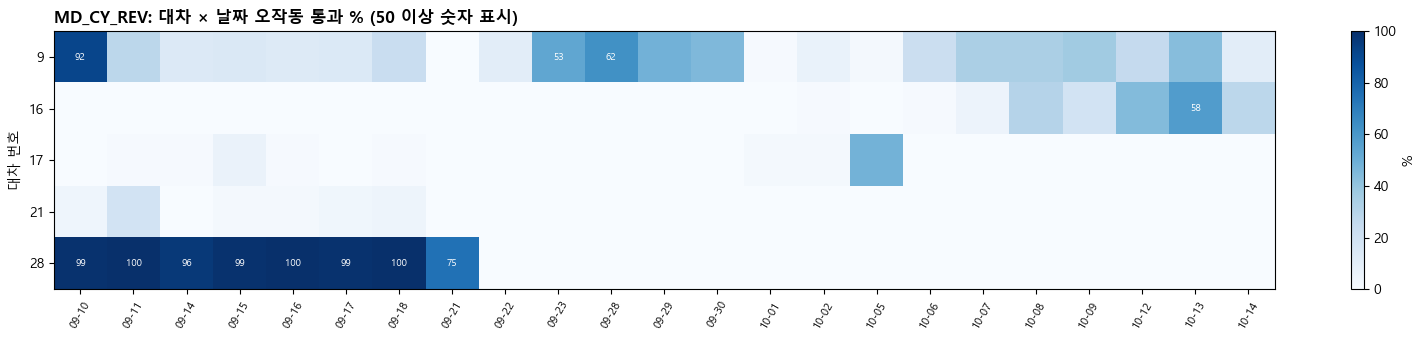

In [6]:
PIV = {}
for n in HIT:
    b = B[n][~B[n]["flat"]]
    piv = b.pivot_table(index="wagon", columns=b["time"].dt.strftime("%m-%d"), values="abnormal", aggfunc="mean").mul(100)
    PIV[n] = piv
    piv.round(1).to_csv(f"{OUT}/wagon_date_{n}.csv", encoding="utf-8-sig")
    p = piv[(piv >= 10).any(axis=1)]
    if p.empty:
        continue
    fig, a = plt.subplots(figsize=(16, 0.34 * len(p) + 1.8))
    im = a.imshow(p.values, aspect="auto", cmap="Blues", vmin=0, vmax=100)
    for (i, jj), v in np.ndenumerate(p.values):
        if v >= 50:
            a.text(jj, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white")
    a.set_yticks(range(len(p))); a.set_yticklabels(p.index); a.set_ylabel("대차 번호")
    a.set_xticks(range(p.shape[1])); a.set_xticklabels(p.columns, rotation=60, fontsize=8)
    a.set_title(f"{n}: 대차 × 날짜 오작동 통과 % (50 이상 숫자 표시)", fontweight="bold", loc="left")
    fig.colorbar(im, ax=a, label="%"); fig.tight_layout(); fig.savefig(f"{OUT}/wagon_date_{n}.png", dpi=100)

## 5. 대차별 패턴 정리
'걸린 날' = 그 날 오작동 통과 50% 이상. 패턴:
- **계속**: 23일 중 90% 이상 걸림
- **사라짐**: 처음엔 걸리다가 마지막 5일(가동일) 동안 안 걸림
- **새로 생김**: 처음 5일 동안 안 걸리다가 이후 걸림
- **들쭉날쭉**: 나머지

In [7]:
def pattern_table(piv, hot=50, edge=5):
    days = list(piv.columns); n = len(days)
    rows = []
    for wg, r in piv.iterrows():
        h = r >= hot
        if not h.any():
            continue
        first, last = h.idxmax(), h[::-1].idxmax()
        if h.mean() >= 0.9:
            pat = "계속"
        elif not h.iloc[-edge:].any():
            pat = "사라짐"
        elif not h.iloc[:edge].any():
            pat = "새로 생김"
        else:
            pat = "들쭉날쭉"
        rows.append({"wagon": wg, "pattern": pat, "hot_days": int(h.sum()), "of_days": n,
                     "first_hot": first, "last_hot": last, "mean_pct": round(r.mean(), 1), "recent5_pct": round(r.iloc[-edge:].mean(), 1)})
    if not rows:
        return pd.DataFrame()
    order = {"계속": 0, "새로 생김": 1, "들쭉날쭉": 2, "사라짐": 3}
    return pd.DataFrame(rows).sort_values(["pattern", "hot_days"], key=lambda s: s.map(order) if s.name == "pattern" else -s).set_index("wagon")

for n in HIT:
    t = pattern_table(PIV[n])
    print(f"■ {n}")
    display(t if len(t) else "50% 넘는 날이 있는 대차 없음")
    if len(t):
        t.to_csv(f"{OUT}/wagon_pattern_{n}.csv", encoding="utf-8-sig")

■ Pour_Zone


'50% 넘는 날이 있는 대차 없음'

■ Conv_Stop


'50% 넘는 날이 있는 대차 없음'

■ MD_CY_FWD


...

,pattern,hot_days,of_days,first_hot,last_hot,mean_pct,recent5_pct
wagon,,,,,,,
20,들쭉날쭉,17,23,09-10,10-13,66.2,53.0


■ Closing


'50% 넘는 날이 있는 대차 없음'

■ MD_CY_REV


,pattern,hot_days,of_days,first_hot,last_hot,mean_pct,recent5_pct
wagon,,,,,,,
16,새로 생김,1,23,10-13,10-13,8.1,35.7
28,사라짐,8,23,09-10,09-21,33.4,0.0
9,사라짐,3,23,09-10,09-28,27.4,29.8


## 6. 50% 는 안 넘지만 가끔 걸리는 것 — Pour_Zone / Conv_Stop / Closing 오작동 목록

In [8]:
for n in ["Pour_Zone", "Conv_Stop", "Closing"]:
    b = B[n][(~B[n]["flat"]) & B[n]["abnormal"]]
    print(f"■ {n}: {len(b)}건, 대차별 {b['wagon'].value_counts().to_dict()}")
    display(b[["time", "wagon", "n_reset", "before_normal", "pour_cnt"]].head(20))

■ Pour_Zone: 3건, 대차별 {13: 1, 26: 1, 5: 1}


,time,wagon,n_reset,before_normal,pour_cnt
47464,2026-09-28 17:43:38.370926,13,2,139.0,6.0
62553,2026-10-02 07:33:11.560451,26,2,140.0,36.0
71689,2026-10-06 08:01:10.675469,5,2,136.0,3.0


■ Conv_Stop: 20건, 대차별 {28: 13, 40: 1, 13: 1, 34: 1, 6: 1, 35: 1, 10: 1, 22: 1}


,time,wagon,n_reset,before_normal,pour_cnt
13055,2026-09-14 22:59:14.123453,28,2,127.0,17.0
14273,2026-09-15 09:47:16.011506,28,2,129.0,19.0
16541,2026-09-15 19:01:57.313278,28,2,133.0,24.0
16793,2026-09-15 20:19:28.892244,28,2,130.0,22.0
17045,2026-09-15 21:13:48.777428,28,2,127.0,20.0
17297,2026-09-15 22:08:09.645952,28,2,131.0,24.0
17465,2026-09-15 22:56:41.735813,28,2,133.0,25.0
17591,2026-09-15 23:23:51.623326,28,2,129.0,23.0
17717,2026-09-15 23:51:01.867681,28,2,132.0,25.0
26747,2026-09-18 07:22:03.651438,28,2,132.0,19.0


■ Closing: 74건, 대차별 {17: 29, 42: 26, 2: 11, 38: 1, 11: 1, 32: 1, 4: 1, 33: 1, 8: 1, 20: 1, 30: 1}


,time,wagon,n_reset,before_normal,pour_cnt
17792,2026-09-16 00:15:11.316983,17,2,122.0,6.0
17834,2026-09-16 06:30:37.131794,17,2,121.0,5.0
17876,2026-09-16 06:39:44.875700,17,2,124.0,8.0
17918,2026-09-16 06:48:52.495570,17,2,124.0,8.0
17960,2026-09-16 06:57:59.827655,17,2,121.0,5.0
18002,2026-09-16 07:07:07.733726,17,2,123.0,7.0
18044,2026-09-16 07:17:42.003546,17,2,125.0,8.0
18086,2026-09-16 07:26:51.380104,17,2,125.0,9.0
18128,2026-09-16 07:36:00.540757,17,2,125.0,8.0
18170,2026-09-16 07:45:09.633905,17,2,122.0,7.0


## 7. 대차별 상세 — '계속 걸린다'가 통과 단위로도 맞나
'걸린 날' = 그 날 오작동 ≥ 50%. 걸린 날 안에서:
- `hot_abn_pct`: 오작동 비율, `hot_normal`: 정상 통과 수, `hot_real_normal`: 그중 리셋 앞뒤 DB 끊김(>0.9초)이 **없었던** 것 = 실제로 깨끗하게 지나간 것
- `hot_real_abn_pct`: DB 끊김 정상 통과를 오작동으로 본 비율(센서는 깜빡였는데 DB 가 못 봤을 수 있음)
- `longest_normal`: 정상 통과가 가장 길게 이어진 횟수, `hours_100`: 1시간(통과 4회 이상) 중 전부 오작동인 시간 %
- `resets_2/3/4+`: 오작동 통과의 리셋 횟수 분포(2 = 한 번 더 깜빡, 3 = 두 번 더)

In [9]:
DET = {}
for n in HIT:
    b = cw.add_pass_context(df, cyc, B[n]); bb = b[~b["flat"]]
    wag = bb.loc[bb["abnormal"], "wagon"].value_counts()
    t = cw.wagon_detail(b, sorted(wag[wag >= 5].index))
    if t.empty:
        continue
    DET[n] = t.sort_values("abn_pct", ascending=False)
    DET[n].to_csv(f"{OUT}/wagon_detail_{n}.csv", encoding="utf-8-sig")
    print(f"■ {n}"); display(DET[n])

■ Conv_Stop


,passes,abn_pct,hot_days,of_days,first_hot,last_hot,hot_abn_pct,hot_normal,hot_real_normal,hot_real_abn_pct,longest_normal,hours_100,resets_2/3/4+
wagon,,,,,,,,,,,,,
28,2387,0.5,0,23,,,NaN,0,0,NaN,0,NaN,13/0/0


■ MD_CY_FWD


,passes,abn_pct,hot_days,of_days,first_hot,last_hot,hot_abn_pct,hot_normal,hot_real_normal,hot_real_abn_pct,longest_normal,hours_100,resets_2/3/4+
wagon,,,,,,,,,,,,,
10,2378,99.5,23,23,09-10,10-14,99.54,11,0,100.00,5,99.0,439/1928/0
19,2378,95.7,23,23,09-10,10-14,95.71,102,91,96.17,5,79.7,1649/627/0
13,2390,95.1,22,23,09-10,10-14,97.85,49,40,98.25,11,95.8,963/1310/1
23,2377,94.9,23,23,09-10,10-14,94.87,122,112,95.29,6,84.4,1101/1154/0
35,2386,94.5,23,23,09-10,10-14,94.51,131,119,95.01,7,84.8,1570/685/0
17,2380,88.0,22,23,09-10,10-13,89.06,254,238,89.75,28,73.5,1294/800/0
28,2387,54.3,12,23,09-10,10-07,85.02,189,176,86.05,27,67.0,1074/223/0
7,2381,45.5,11,23,09-21,10-14,96.87,35,34,96.96,32,96.7,50/1034/0
9,2382,42.1,9,23,09-10,09-22,96.82,30,24,97.45,24,96.2,103/900/0


■ Opening


,passes,abn_pct,hot_days,of_days,first_hot,last_hot,hot_abn_pct,hot_normal,hot_real_normal,hot_real_abn_pct,longest_normal,hours_100,resets_2/3/4+
wagon,,,,,,,,,,,,,
20,2377,66.8,17,23,09-10,10-13,78.84,380,370,79.4,32,41.9,1587/1/0
28,2385,2.0,0,23,,,NaN,0,0,NaN,0,NaN,47/0/0


■ Closing


,passes,abn_pct,hot_days,of_days,first_hot,last_hot,hot_abn_pct,hot_normal,hot_real_normal,hot_real_abn_pct,longest_normal,hours_100,resets_2/3/4+
wagon,,,,,,,,,,,,,
17,2379,1.2,0,23,,,NaN,0,0,NaN,0,NaN,29/0/0
42,2381,1.1,0,23,,,NaN,0,0,NaN,0,NaN,7/19/0
2,2377,0.5,0,23,,,NaN,0,0,NaN,0,NaN,11/0/0


■ MD_CY_REV


,passes,abn_pct,hot_days,of_days,first_hot,last_hot,hot_abn_pct,hot_normal,hot_real_normal,hot_real_abn_pct,longest_normal,hours_100,resets_2/3/4+
wagon,,,,,,,,,,,,,
28,2386,33.7,8,23,09-10,09-21,95.95,34,28,96.66,25,93.5,157/648/0
9,2377,27.9,3,23,09-10,09-28,68.92,101,101,68.92,7,25.5,636/28/0
16,2386,7.7,1,23,10-13,10-13,57.69,44,44,57.69,5,0.0,157/26/0
17,2380,2.8,0,23,,,NaN,0,0,NaN,0,NaN,64/2/0
21,2386,1.6,0,23,,,NaN,0,0,NaN,0,NaN,38/0/0
23,2380,0.5,0,23,,,NaN,0,0,NaN,0,NaN,12/0/0
13,2385,0.5,0,23,,,NaN,0,0,NaN,0,NaN,11/0/0
10,2386,0.4,0,23,,,NaN,0,0,NaN,0,NaN,9/0/0
1,2380,0.3,0,23,,,NaN,0,0,NaN,0,NaN,8/0/0


## 8. 대차가 켜지고 꺼지는 시점 — 정지 직후에 몰리나
같은 대차 통과 순서에서 앞 15회와 뒤 15회 오작동 비율이 80%p 이상 바뀐 곳 = 전환.
`gap_min` = 그 통과 직전 같은 대차 통과와의 간격(한 바퀴 ≈ 9.1분). 11분 넘으면 사이에 정지가 있었던 것.

In [10]:
SW, base = cw.find_switches(B)
print(f"아무 통과 사이에 정지가 낀 비율(기준): {base:.1f}%")
print(f"전환 {len(SW)}건 중 정지 직후: {int(SW['after_stop'].sum())}건 ({SW['after_stop'].mean() * 100:.0f}%)")
SW.to_csv(f"{OUT}/switches.csv", index=False, encoding="utf-8-sig")
display(SW)

아무 통과 사이에 정지가 낀 비율(기준): 9.7%
전환 41건 중 정지 직후: 31건 (76%)


,counter,wagon,time,dir,before_pct,after_pct,gap_min,after_stop
0,MD_CY_FWD,30,2026-09-14 05:12:34.344013,꺼짐,100,0,3198.3,True
1,MD_CY_FWD,17,2026-09-16 06:26:57.908844,꺼짐,100,0,392.5,True
2,MD_CY_FWD,17,2026-09-16 11:27:39.341008,켜짐,0,100,40.6,True
3,MD_CY_FWD,27,2026-09-16 19:41:45.838798,꺼짐,100,0,21.9,True
4,MD_CY_FWD,20,2026-09-17 15:33:26.338171,꺼짐,80,0,14.6,True
5,MD_CY_FWD,20,2026-09-18 00:37:02.067602,켜짐,7,100,32.9,True
6,MD_CY_REV,9,2026-09-18 11:22:33.818121,꺼짐,93,0,33.1,True
7,MD_CY_FWD,4,2026-09-18 12:34:28.079204,꺼짐,100,0,10.5,False
8,MD_CY_FWD,20,2026-09-18 15:24:19.060027,꺼짐,100,0,9.1,False
9,MD_CY_FWD,21,2026-09-21 05:50:32.145166,켜짐,0,100,3232.8,True


## 9. 대차 번호 검증과 해석 근거
'특정 센서 × 특정 대차' 에서만 오작동이 나는 이유를 보기 위한 확인들.

### 9-1. 1번감지 센서로 번호 차이 확인
1번 대차가 전진/후진 Unit 을 지날 때 켜지는 센서. 켜진 순간의 통과가 Pour 기준 몇 번(pour_wagon)으로 붙었는지 본다. 하나로 모이면 그 값 - 1 이 차이다.

In [11]:
import conv_wagon_no1_pull as c1
importlib.reload(c1)
N1 = c1.load_days()
rows = []
for n, tag in c1.NO1_TAGS.items():
    s = N1[tag].dropna(); s = s[~s.index.duplicated()]
    on = s.index[(s == 1) & (s.shift() != 1)]
    b = B[n][~B[n]["flat"]].sort_values("time").reset_index(drop=True)
    j = np.clip(np.searchsorted(b["time"].values, on.values), 1, len(b) - 1)
    j = np.where(np.abs(b["time"].values[j - 1] - on.values) < np.abs(b["time"].values[j] - on.values), j - 1, j)
    dt = (on.values - b["time"].values[j]) / np.timedelta64(1, "s")
    ok = np.abs(dt) < 6
    pw = b["pour_wagon"].values[j][ok]; real = b["wagon"].values[j][ok]
    rows.append({"counter": n, "센서": tag, "켜진 횟수": len(on), "통과와 매칭": int(ok.sum()),
                 "시각차 중앙(초)": float(np.median(dt[ok])),
                 "pour_wagon 분포": pd.Series(pw).value_counts().head(3).to_dict(),
                 "→ 차이(LABEL_OFFSET)": cw.LABEL_OFFSET[n], "실제 번호 분포": pd.Series(real).value_counts().head(3).to_dict()})
display(pd.DataFrame(rows).set_index("counter"))

,센서,켜진 횟수,통과와 매칭,시각차 중앙(초),pour_wagon 분포,→ 차이(LABEL_OFFSET),실제 번호 분포
counter,,,,,,,
MD_CY_FWD,전진Unit 캐리어 1번감지,1488,1477,0.0,{28: 1477},27,{1: 1477}
MD_CY_REV,후진Unit 캐리어 1번감지,1718,1705,0.0,{42: 1705},41,{1: 1705}


### 9-2. Opening → 전진Unit 은 같은 대차인가 (현장: Opening 에 2번이 들어오면 바로 뒤 전진Unit 도 2번)

In [12]:
o = B["Opening"][~B["Opening"]["flat"]].sort_values("time"); f = B["MD_CY_FWD"][~B["MD_CY_FWD"]["flat"]].sort_values("time")
i = np.searchsorted(o["time"].values, f["time"].values) - 1; ok = i >= 0
d = pd.DataFrame({"초": (f["time"].values[ok] - o["time"].values[i[ok]]) / np.timedelta64(1, "s"),
                  "pour_wagon 차이": (f["pour_wagon"].values[ok] - o["pour_wagon"].values[i[ok]]) % 42,
                  "실제 번호 차이": (f["wagon"].values[ok] - o["wagon"].values[i[ok]]) % 42})
d = d[d["초"] < 20]
print("Opening 통과 → 다음 FWD 통과 시간(초):", d["초"].describe()[["25%", "50%", "75%"]].round(2).to_dict())
display(pd.DataFrame({c: d[c].value_counts().head(3) for c in ["pour_wagon 차이", "실제 번호 차이"]}))

Opening 통과 → 다음 FWD 통과 시간(초): {'25%': 4.14, '50%': 4.21, '75%': 4.7}


,pour_wagon 차이,실제 번호 차이
0,1.0,99720.0
1,99720.0,6.0
2,6.0,NaN
41,NaN,1.0


### 9-3. 대차 간격 무늬 — 모든 센서가 같은 대차를 같은 번호로 보나
여섯 카운터는 같은 엔코더로 올라간다 → 리셋 위치를 엔코더로 되살리면 대차 간격(정위치 리셋 사이)이 나온다.
정상 간격은 139 인데 **연속 5~6대만 142~143** 이다. 실제 번호로 바꾼 뒤 모든 센서에서 같은 대차에 나타나면 번호가 맞은 것이다(Conv_Stop·Closing 은 이것만이 근거).

In [13]:
ENC = cw.encoder(df)
d = np.diff(df[cw.CNT_TAGS].values, axis=0); pos = np.where(d > 0, d, np.nan)
with np.errstate(all="ignore"):
    same = np.nanmax(pos, axis=1) == np.nanmin(pos, axis=1)
print(f"샘플마다 여섯 카운터 증가량이 같은 비율: {np.nanmean(same) * 100:.1f}%")
G = {n: cw.pass_geometry(df, R[n], ENC) for n in cw.COUNTERS}
PITCH = pd.DataFrame({n: G[n][~G[n]["abnormal"]].groupby("wagon")["pitch"].median() for n in cw.COUNTERS})
display(PITCH.round(0).astype("Int64").T)
ref = PITCH["Pour_Zone"].values
print("Pour 와 간격 무늬 상관 (번호 그대로 / 가장 잘 맞는 밀기):")
for n in cw.COUNTERS:
    cs = [np.corrcoef(ref, np.roll(PITCH[n].values, -k))[0, 1] for k in range(42)]
    print(f"  {n:9s} 0칸: {cs[0]:.2f}   최고: {int(np.argmax(cs))}칸 {max(cs):.2f}")

샘플마다 여섯 카운터 증가량이 같은 비율: 99.7%


wagon,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42
Pour_Zone,138,139,139,139,138,139,143,142,143,142,143,142,139,139,138,139,139,139,138,139,139,139,138,140,138,139,139,138,139,139,139,139,137,140,138,139,139,139,138,139,139,139
Conv_Stop,139,139,139,138,139,139,143,142,142,143,142,143,139,138,139,139,139,139,138,139,139,139,138,139,139,138,140,138,139,138,139,139,138,139,139,139,139,139,138,139,138,139
MD_CY_FWD,143,138,140,138,139,139,142,143,142,136,142,143,139,133,145,139,139,139,128,141,139,139,128,139,138,139,139,139,138,139,139,135,138,139,139,139,138,139,139,139,138,135
Opening,139,138,139,139,139,139,142,142,143,142,143,142,139,139,138,139,139,139,139,132,140,139,138,139,138,139,139,138,139,139,139,139,138,139,139,139,138,139,139,138,139,139
Closing,138,139,139,139,138,139,143,142,143,142,143,142,139,139,138,139,139,139,138,139,139,139,138,139,139,139,139,138,139,139,139,139,139,139,139,138,139,139,138,139,139,139
MD_CY_REV,139,138,140,138,139,139,142,143,142,142,143,143,138,139,139,139,139,138,139,139,139,139,139,139,138,139,139,139,138,139,139,139,138,139,139,139,138,139,139,138,139,139


Pour 와 간격 무늬 상관 (번호 그대로 / 가장 잘 맞는 밀기):
  Pour_Zone 0칸: 1.00   최고: 0칸 1.00
  Conv_Stop 0칸: 0.89   최고: 0칸 0.89
  MD_CY_FWD 0칸: 0.36   최고: 0칸 0.36
  Opening   0칸: 0.72   최고: 0칸 0.72
  Closing   0칸: 0.95   최고: 0칸 0.95
  MD_CY_REV 0칸: 0.86   최고: 0칸 0.86


### 9-4. 실제 번호로 본 센서 × 대차 오작동 % (기간 전체)
어느 센서에서라도 5% 넘는 대차만.

In [14]:
PH = pd.DataFrame({n: B[n][~B[n]["flat"]].groupby("wagon")["abnormal"].mean().mul(100) for n in cw.COUNTERS}).reindex(range(1, 43))
PH.index.name = "실제 대차"
t = PH[(PH >= 5).any(axis=1)].round(1)
display(t.style.background_gradient(cmap="Blues", vmin=0, vmax=100).format("{:.1f}"))
PH.round(2).to_csv(f"{OUT}/real_wagon_x_counter.csv", encoding="utf-8-sig")

,Pour_Zone,Conv_Stop,MD_CY_FWD,Opening,Closing,MD_CY_REV
실제 대차,,,,,,
4,0.0,0.0,27.8,0.0,0.0,0.0
7,0.0,0.0,45.5,0.0,0.0,0.0
9,0.0,0.0,42.1,0.0,0.0,27.9
10,0.0,0.0,99.5,0.0,0.0,0.4
13,0.0,0.0,95.1,0.0,0.0,0.5
14,0.0,0.0,21.4,0.0,0.0,0.0
16,0.0,0.0,31.4,0.0,0.0,7.7
17,0.0,0.0,88.0,0.0,1.2,2.8
19,0.0,0.0,95.7,0.0,0.0,0.0


### 9-5. 같은 대차가 두 센서에서 같은 시각에 꺼졌나

In [15]:
def hourly(n, wagon, s, e):
    b = B[n]; x = b[(~b["flat"]) & (b["wagon"] == wagon) & (b["time"] >= s) & (b["time"] < e)]
    return x.groupby(x["time"].dt.floor("h"))["abnormal"].mean().mul(100).round(0)
for wagon, s, e in [(28, "2026-09-21 14:00", "2026-09-21 23:00"), (16, "2026-10-14 06:00", "2026-10-14 17:00"), (20, "2026-09-22 06:00", "2026-09-22 20:00")]:
    names = [n for n in cw.COUNTERS if PH.loc[wagon, n] >= 5]
    tt = pd.DataFrame({n: hourly(n, wagon, s, e) for n in names}).T
    tt.columns = tt.columns.strftime("%m-%d %H시")
    print(f"■ 실제 {wagon}번 대차 — 시간별 오작동 %"); display(tt)

■ 실제 28번 대차 — 시간별 오작동 %


time,09-21 14시,09-21 15시,09-21 16시,09-21 17시,09-21 18시,09-21 19시,09-21 20시,09-21 21시,09-21 22시
MD_CY_FWD,100.0,100.0,100.0,100.0,100.0,75.0,0.0,0.0,0.0
MD_CY_REV,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0,0.0


■ 실제 16번 대차 — 시간별 오작동 %


time,10-14 06시,10-14 07시,10-14 08시,10-14 09시,10-14 10시,10-14 11시,10-14 12시,10-14 13시,10-14 14시,10-14 15시,10-14 16시
MD_CY_FWD,100.0,100.0,100.0,100.0,83.0,0.0,0.0,0.0,0.0,0.0,100.0
MD_CY_REV,75.0,71.0,60.0,43.0,20.0,0.0,0.0,0.0,0.0,0.0,NaN


■ 실제 20번 대차 — 시간별 오작동 %


time,09-22 06시,09-22 07시,09-22 08시,09-22 09시,09-22 10시,09-22 11시,09-22 12시,09-22 13시,09-22 14시,09-22 15시,09-22 16시,09-22 17시,09-22 18시,09-22 19시
MD_CY_FWD,60.0,14.0,20.0,33.0,50.0,50.0,57.0,0.0,57.0,33.0,0.0,0.0,0.0,0.0
Opening,100.0,100.0,100.0,100.0,100.0,0.0,14.0,20.0,57.0,0.0,0.0,17.0,0.0,0.0


### 9-6. 깜빡임 모양 — 거리 주기인가 시간 주기인가
- `early`: 첫 리셋이 정위치(마지막 리셋)보다 몇 카운트 일찍 났나
- 리셋 사이 간격을 속도 구간별로 본다. **카운트로 일정하고 초가 바뀌면 거리 주기**(대차·레일의 모양), 초로 일정하면 시간 주기(노이즈·스캔).

In [16]:
tsec = (df.index - df.index[0]).total_seconds().values
rows = []
for n in ["MD_CY_FWD", "MD_CY_REV", "Opening"]:
    r = R[n][~R[n]["flat"]].copy(); j = df.index.get_indexer(r["time"])
    lo, hi = np.clip(j - 5, 0, None), np.clip(j + 5, None, len(ENC) - 1)
    r["spd"] = (ENC[hi] - ENC[lo]) / (tsec[hi] - tsec[lo])
    r["enc"] = ENC[j] - r["after"].values
    r["t_est"] = tsec[j] - r["after"].values / r["spd"].values
    r["d_cnt"] = r.groupby("burst")["enc"].diff(); r["d_s"] = r.groupby("burst")["t_est"].diff()
    e = r[r["abnormal"] & r["d_cnt"].notna()].copy()
    e["속도(카운트/초)"] = pd.cut(e["spd"], [0, 10, 10.5, 11, 11.5, 20])
    t = e.groupby("속도(카운트/초)").agg(건수=("d_cnt", "size"), 간격_카운트=("d_cnt", "median"), 간격_초=("d_s", "median"))
    t.insert(0, "counter", n); rows.append(t[t["건수"] >= 20])
    g = G[n][G[n]["abnormal"]]
    print(f"{n}: 오작동 통과의 early 중앙 {g['early'].median():.0f} 카운트, 오작동 통과 간격 중앙 {g['pitch'].median():.0f} (정상 {G[n][~G[n]['abnormal']]['pitch'].median():.0f})")
display(pd.concat(rows).round(2))

MD_CY_FWD: 오작동 통과의 early 중앙 14 카운트, 오작동 통과 간격 중앙 139 (정상 139)
MD_CY_REV: 오작동 통과의 early 중앙 14 카운트, 오작동 통과 간격 중앙 139 (정상 139)


Opening: 오작동 통과의 early 중앙 7 카운트, 오작동 통과 간격 중앙 138 (정상 139)


,counter,건수,간격_카운트,간격_초
속도(카운트/초),,,,
"(0.0, 10.0]",MD_CY_FWD,5811,7.0,0.83
"(10.0, 10.5]",MD_CY_FWD,4416,7.0,0.72
"(10.5, 11.0]",MD_CY_FWD,3136,7.0,0.69
"(11.0, 11.5]",MD_CY_FWD,20984,7.0,0.67
"(11.5, 20.0]",MD_CY_FWD,72,8.0,0.69
"(10.0, 10.5]",MD_CY_REV,126,13.0,1.24
"(10.5, 11.0]",MD_CY_REV,547,10.0,0.96
"(11.0, 11.5]",MD_CY_REV,1819,7.0,0.68
"(0.0, 10.0]",Opening,73,6.0,0.69


### 9-7. 센서마다 '대차별 검출 위치' 가 얼마나 들쭉날쭉한가 (정상 통과 간격의 대차 간 범위)

In [17]:
display(pd.DataFrame({"평균": PITCH.mean(), "표준편차": PITCH.std(), "최소": PITCH.min(), "최대": PITCH.max(),
                      "범위": PITCH.max() - PITCH.min()}).round(1))

,평균,표준편차,최소,최대,범위
Pour_Zone,139.3,1.5,137.0,143.0,6.0
Conv_Stop,139.3,1.4,138.0,143.0,5.0
MD_CY_FWD,138.6,3.3,128.0,145.0,17.0
Opening,139.1,1.7,132.0,143.0,11.0
Closing,139.3,1.4,138.0,143.0,5.0
MD_CY_REV,139.3,1.4,138.0,143.0,5.0


### 9-8. 해석
| 관찰 | 뜻 |
|---|---|
| 다른 센서에서 걸린 대차는 (Opening 20번 하나 빼고) MD_CY_FWD 에서도 걸린다. FWD '계속' 대차는 다른 센서에선 0% | 원인은 대차 쪽, **센서마다 감지 여유가 달라** 드러나는 정도가 다르다. FWD 가 가장 민감 |
| 같은 대차가 FWD·REV 에서 같은 정지 직후 동시에 꺼짐(28번 9/21 20시, 16번 10/14 11시) | 센서가 아니라 **그 대차의 상태가 정지 중 바뀜** |
| 오작동 통과 = 첫 리셋이 정위치보다 ~14카운트 일찍, 이후 7카운트마다 재리셋. 간격이 속도와 무관하게 카운트로 일정 | 전기 노이즈가 아니라 **물리적 모양**: 정위치 앞쪽 무언가가 센서 감지 경계에 걸쳐 있음 |
| 대차별 검출 위치 범위 FWD 17 vs 다른 센서 5~6 | FWD 센서는 대차마다 차이가 큰 부위를 보거나, 대차 위치가 흔들리는 곳에 있음 |
| 켜짐↔꺼짐 전환 76% 가 정지 직후 (기준 10%) | 정지 중 대차 자리 잡힘·조정이 상태를 바꿈 |

현장 확인: 실제 10번(FWD 매번) 대차 앞부분 vs 정상 대차, 7카운트가 몇 mm 인지(체인 피치 등 반복 구조?), FWD 센서 거리·각도, 9/21 19:31~20:03·10/14 11시 전후 작업 기록.

## 10. 라인 알람(AL_Line_Word) 과 오작동 리셋이 겹치나
`AL_Line_Word` = 에러 번호(매핑표는 현장). 0 이 아닌 값으로 바뀐 구간을 알람 1건으로 본다.
데이터 받기: `PYTHONIOENCODING=utf-8 python parkkt/conv/conv_alarm_pull.py`

- `moving_before`: 알람 시작 전 10초 안에 컨베이어가 움직였나(False 면 이미 서 있을 때 뜬 알람)
- 겹침: 알람 시작 **직전 2초** 안에 오작동 리셋이 있었나. MD_CY_FWD 는 원래 오작동이 잦아서 아무 시각을 잡아도 몇 % 는 겹친다 → 기준과 비교

In [18]:
import conv_alarm_pull as ca
importlib.reload(ca)
AL = ca.load_days(); AL = AL[~AL.index.duplicated()].sort_index()
E = cw.alarm_events(AL, df[cw.COUNTERS["Pour_Zone"][0]])
print("나온 코드:", sorted(E["code"].unique()))
print("관심 코드 중 한 번도 없는 것:", [c for c in [71, 81, 27, 28, 29] if c not in set(E["code"])])
display(E.groupby("code").agg(건수=("dur_s", "size"), 지속_중앙초=("dur_s", "median"), 지속_최대초=("dur_s", "max"),
                             움직이다_뜬_비율=("moving_before", "mean"), 멈춘뒤_중앙초=("since_move_s", "median")).round(2))
E.to_csv(f"{OUT}/alarm_events.csv", index=False, encoding="utf-8-sig")

나온 코드: [np.int64(5), np.int64(6), np.int64(9), np.int64(14), np.int64(15), np.int64(25), np.int64(30), np.int64(33), np.int64(34), np.int64(37), np.int64(38), np.int64(42), np.int64(43), np.int64(44), np.int64(55), np.int64(60), np.int64(71), np.int64(81), np.int64(103), np.int64(107), np.int64(111)]
관심 코드 중 한 번도 없는 것: [27, 28, 29]


,건수,지속_중앙초,지속_최대초,움직이다_뜬_비율,멈춘뒤_중앙초
code,,,,,
5,1,8.94,8.94,1.00,0.53
6,4,4.84,6.22,1.00,0.52
9,1,4.73,4.73,1.00,0.53
14,2,7.95,11.08,1.00,0.52
15,1,4.68,4.68,1.00,0.53
25,7,2.11,4.17,0.00,228.40
30,1,11.00,11.00,1.00,0.54
33,6,7.95,145.06,1.00,0.52
34,1,2.74,2.74,1.00,0.52


In [19]:
L, rate = cw.alarm_link(E, R, win_s=2.0)
base = cw.baseline_rate(df, R, win_s=2.0)
print("기준: 컨베이어가 움직이는 아무 시각에서 직전 2초 안에 오작동 리셋이 있었던 비율 %"); display(base.to_frame("기준 %").T)
print("코드별: 알람 시작 직전 2초 안에 오작동 리셋이 있었던 비율 %"); display(rate)
L.to_csv(f"{OUT}/alarm_link.csv", index=False, encoding="utf-8-sig")
print("오작동 리셋과 겹친 알람 (값 = 그 카운터에서 오작동 난 실제 대차 번호)")
display(L[(L[list(R)] != "").any(axis=1)])

기준: 컨베이어가 움직이는 아무 시각에서 직전 2초 안에 오작동 리셋이 있었던 비율 %


,Pour_Zone,Conv_Stop,MD_CY_FWD,Opening,Closing,MD_CY_REV
기준 %,0.0,0.0,4.1,0.2,0.0,0.2


코드별: 알람 시작 직전 2초 안에 오작동 리셋이 있었던 비율 %


,events,Pour_Zone,Conv_Stop,MD_CY_FWD,Opening,Closing,MD_CY_REV
code,,,,,,,
5,1,0.0,0.0,0.0,0.0,0.0,0.0
6,4,0.0,0.0,25.0,0.0,0.0,0.0
9,1,0.0,0.0,0.0,0.0,0.0,0.0
14,2,0.0,0.0,0.0,0.0,0.0,0.0
15,1,0.0,0.0,0.0,0.0,0.0,0.0
25,7,0.0,0.0,0.0,0.0,0.0,0.0
30,1,0.0,0.0,0.0,0.0,0.0,0.0
33,6,0.0,0.0,100.0,0.0,16.7,0.0
34,1,0.0,0.0,0.0,0.0,0.0,0.0


오작동 리셋과 겹친 알람 (값 = 그 카운터에서 오작동 난 실제 대차 번호)


,code,start,dur_s,Pour_Zone,Conv_Stop,MD_CY_FWD,Opening,Closing,MD_CY_REV
6,111,2026-09-11 17:56:15.965376,17.453037,,,,,,1
7,111,2026-09-14 05:18:32.422206,829.538492,,,,,,1
8,111,2026-09-14 06:27:52.454167,59.062056,,,,,,1
9,111,2026-09-14 06:38:03.443080,76.792760,,,,,,1
10,111,2026-09-14 06:48:34.383403,86.270556,,,,,,1
11,111,2026-09-14 06:59:14.890634,15.787558,,,,,,1
12,111,2026-09-14 07:12:37.630047,13.097617,,,,,,1
13,111,2026-09-14 07:21:53.945181,21.796051,,,,,,1
14,111,2026-09-14 07:31:06.835544,24.546677,,,,,,1
20,33,2026-09-15 11:08:38.987188,8.979562,,,19,,,


### 10-1. 반대로 — 그 오작동이 나면 알람이 매번 뜨나 (코드 111 ↔ MD_CY_REV, 코드 33 ↔ MD_CY_FWD)

In [20]:
for n, code in [("MD_CY_REV", 111), ("MD_CY_FWD", 33)]:
    r = R[n]; last = r.groupby("burst")["time"].max()
    b = B[n][B[n]["abnormal"]].copy(); b["last"] = b["burst"].map(last)
    at = np.sort(E.loc[E["code"] == code, "start"].values)
    k = np.searchsorted(at, b["last"].values - np.timedelta64(1, "s"))
    b["alarm"] = [(kk < len(at)) and (at[kk] - t) / np.timedelta64(1, "s") <= 2 for kk, t in zip(k, b["last"].values)]
    t = b.groupby("wagon").agg(오작동_통과=("alarm", "size"), 알람=("alarm", "sum"))
    t["알람률_%"] = (t["알람"] / t["오작동_통과"] * 100).round(2)
    print(f"■ {n} 오작동 통과 → 코드 {code}: 알람 난 대차만 (전체 오작동 통과 {len(b)}, 알람 {int(b['alarm'].sum())})")
    display(t[t["알람"] > 0])
    if n == "MD_CY_REV":
        print("  MD_CY_REV 실제 1번 대차 오작동 통과 수:", int((b["wagon"] == 1).sum()))
    else:
        print("  MD_CY_FWD 실제 1번 대차 오작동 통과 수:", int((b["wagon"] == 1).sum()))

■ MD_CY_REV 오작동 통과 → 코드 111: 알람 난 대차만 (전체 오작동 통과 1820, 알람 12)


,오작동_통과,알람,알람률_%
wagon,,,
1,12,12,100.0


  MD_CY_REV 실제 1번 대차 오작동 통과 수: 12
■ MD_CY_FWD 오작동 통과 → 코드 33: 알람 난 대차만 (전체 오작동 통과 23787, 알람 6)


,오작동_통과,알람,알람률_%
wagon,,,
17,2105,1,0.05
19,2291,5,0.22


  MD_CY_FWD 실제 1번 대차 오작동 통과 수: 0


### 10-2. 정리
| 코드 | 언제 | 오작동 리셋과 관계 |
|---|---|---|
| **111** | 가동 중 | **MD_CY_REV 에서 실제 1번 대차가 두 번 감지되면 매번(12/12) 뜬다. 111 전부가 이 경우.** 1번 대차는 1번감지 센서로 번호를 맞추는 대차 → 대차 번호 추적 이상 알람으로 추정(코드 뜻 확인 필요) |
| **33** | 가동 중 | 6건 전부 MD_CY_FWD 오작동 리셋과 같은 샘플(실제 19번 5건, 17번 1건). 하지만 그 두 대차 오작동 4,396번 중 6번(0.1%)뿐 → 다른 조건이 더 있음(코드 뜻 확인 필요) |
| 71, 81, 25 | **이미 멈춘 뒤**(중앙 4~5분), 쉬는 시간(0·11·19시) | 겹침 없음. 알람이 끝나고 4~8초 뒤 컨베이어가 다시 돈다 → 재가동 관련 알람으로 보임. 71 은 10/13 까지, 81 은 9/21 부터 |
| 27, 28, 29 | — | 9/10~10/14 평일에 한 번도 없음 |
| 6, 38, 44, 30 | 가동 중 | 1건씩만 오작동과 겹침(6: FWD 23번, 38: FWD 42번, 44: FWD 10번·Opening 20번, 30: REV 28번) — 건수가 적어 판단 보류 |